<table class="table table-bordered">
    <tr>
        <th style="text-align:center;"><h1>Data Wrangling</h1><h2>Assignment</h2><h3>Diploma in Data Science</h3></th>
    </tr>
</table>

In [102]:
# import the pacakges
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

%matplotlib inline 

### Step 1: Load and Explore the Data

In [103]:
# loadind the 4 tables
salary = pd.read_csv('./datasets/CSV/salary.csv') #  player salary
player = pd.read_csv('./datasets/CSV/player.csv') # personal information about each player
appearances = pd.read_csv('./datasets/CSV/appearances.csv')# how often each player played
team = pd.read_csv('./datasets/CSV/team.csv')  # information about each team performance

# checking number of rows and coloumns
print('salary:', salary.shape)
print('player:', player.shape)
print('team:', team.shape)
print('appearances:', appearances.shape)

salary: (25575, 5)
player: (18846, 24)
team: (2805, 48)
appearances: (100951, 21)


##### Exploring Salary Table

In [104]:
# showing first 5 rows of salary table
salary.head()

,year,team_id,league_id,player_id,salary
0,1985,ATL,NL,barkele01,870000
1,1985,ATL,NL,bedrost01,550000
2,1985,ATL,NL,benedbr01,545000
3,1985,ATL,NL,campri01,633333
4,1985,ATL,NL,ceronri01,625000


In [105]:
salary.info() # checking data type
salary.isna().sum() # checking missing values

<class 'pandas.DataFrame'>
RangeIndex: 25575 entries, 0 to 25574
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   year       25575 non-null  int64
 1   team_id    25575 non-null  str  
 2   league_id  25575 non-null  str  
 3   player_id  25575 non-null  str  
 4   salary     25575 non-null  int64
dtypes: int64(2), str(3)
memory usage: 999.2 KB


year         0
team_id      0
league_id    0
player_id    0
salary       0
dtype: int64

In [106]:
salary['salary'].describe() # basic stats for salary

# count = 25,575 non-missing salary values
# mean = average salary is $2,008,563
# std = $3,315,706
# min = lowest salary is 0
# 25% = 25% of salaries are $275,000 or below
# 50% = median salary is $550,000
# 75% = 75% of salaries are $2,250,000 or below
# max = highest salary is $33,000,000

count    2.557500e+04
mean     2.008563e+06
std      3.315706e+06
min      0.000000e+00
25%      2.750000e+05
50%      5.500000e+05
75%      2.250000e+06
max      3.300000e+07
Name: salary, dtype: float64

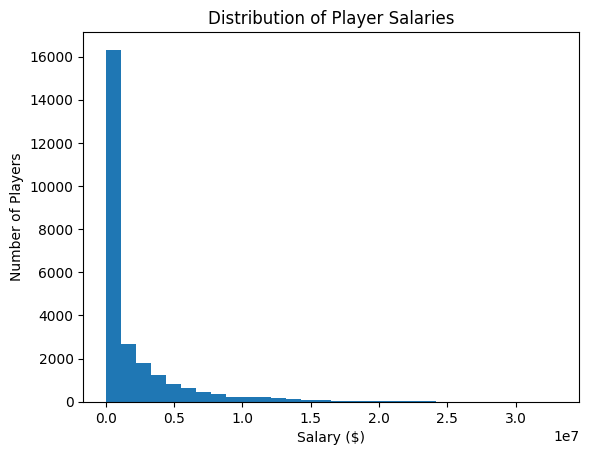

In [107]:
# plotting the distribution of player salaries
plt.hist(salary['salary'], bins=30)

plt.title('Distribution of Player Salaries')
plt.xlabel('Salary ($)')
plt.ylabel('Number of Players')

plt.show()

The salary distribution chart shows that it is highly right skewed. Most player salaries are concentrated in the lower salary range, while a small number of players earn much higher salaries.

In [108]:
# finding the year range for salary table
print("Salary year range:", 
    salary['year'].min(),
    "-",
     salary['year'].max()
)

Salary year range: 1985 - 2015


##### Exploring Player Table

In [109]:
# showing first 5 rows of player table
player.head()

,player_id,birth_year,birth_month,birth_day,birth_country,birth_state,birth_city,death_year,death_month,death_day,...,name_last,name_given,weight,height,bats,throws,debut,final_game,retro_id,bbref_id
0,aardsda01,1981.0,12.0,27.0,USA,CO,Denver,NaN,NaN,NaN,...,Aardsma,David Allan,220.0,75.0,R,R,2004-04-06,2015-08-23,aardd001,aardsda01
1,aaronha01,1934.0,2.0,5.0,USA,AL,Mobile,NaN,NaN,NaN,...,Aaron,Henry Louis,180.0,72.0,R,R,1954-04-13,1976-10-03,aaroh101,aaronha01
2,aaronto01,1939.0,8.0,5.0,USA,AL,Mobile,1984.0,8.0,16.0,...,Aaron,Tommie Lee,190.0,75.0,R,R,1962-04-10,1971-09-26,aarot101,aaronto01
3,aasedo01,1954.0,9.0,8.0,USA,CA,Orange,NaN,NaN,NaN,...,Aase,Donald William,190.0,75.0,R,R,1977-07-26,1990-10-03,aased001,aasedo01
4,abadan01,1972.0,8.0,25.0,USA,FL,Palm Beach,NaN,NaN,NaN,...,Abad,Fausto Andres,184.0,73.0,L,L,2001-09-10,2006-04-13,abada001,abadan01


In [110]:
player.info() # checking data type
player.isna().sum() # checking missing values

<class 'pandas.DataFrame'>
RangeIndex: 18846 entries, 0 to 18845
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   player_id      18846 non-null  str    
 1   birth_year     18703 non-null  float64
 2   birth_month    18531 non-null  float64
 3   birth_day      18382 non-null  float64
 4   birth_country  18773 non-null  str    
 5   birth_state    18220 non-null  str    
 6   birth_city     18647 non-null  str    
 7   death_year     9336 non-null   float64
 8   death_month    9335 non-null   float64
 9   death_day      9334 non-null   float64
 10  death_country  9329 non-null   str    
 11  death_state    9277 non-null   str    
 12  death_city     9325 non-null   str    
 13  name_first     18807 non-null  str    
 14  name_last      18846 non-null  str    
 15  name_given     18807 non-null  str    
 16  weight         17975 non-null  float64
 17  height         18041 non-null  float64
 18  bats           17

player_id           0
birth_year        143
birth_month       315
birth_day         464
birth_country      73
birth_state       626
birth_city        199
death_year       9510
death_month      9511
death_day        9512
death_country    9517
death_state      9569
death_city       9521
name_first         39
name_last           0
name_given         39
weight            871
height            805
bats             1191
throws            978
debut             193
final_game        193
retro_id           54
bbref_id            1
dtype: int64

##### Exploring Appearances Table

In [111]:
# Showing first 5 rows of appearances table
appearances.head()

,year,team_id,league_id,player_id,g_all,gs,g_batting,g_defense,g_p,g_c,...,g_2b,g_3b,g_ss,g_lf,g_cf,g_rf,g_of,g_dh,g_ph,g_pr
0,1871,BS1,NaN,barnero01,31.0,NaN,31,31.0,0,0,...,16,0,15,0,0,0,0,NaN,NaN,NaN
1,1871,BS1,NaN,barrofr01,18.0,NaN,18,18.0,0,0,...,1,0,0,13,0,4,17,NaN,NaN,NaN
2,1871,BS1,NaN,birdsda01,29.0,NaN,29,29.0,0,7,...,0,0,0,0,0,27,27,NaN,NaN,NaN
3,1871,BS1,NaN,conefr01,19.0,NaN,19,19.0,0,0,...,0,0,0,18,0,1,18,NaN,NaN,NaN
4,1871,BS1,NaN,gouldch01,31.0,NaN,31,31.0,0,0,...,0,0,0,0,0,1,1,NaN,NaN,NaN


In [112]:
appearances.info() # checking data type
appearances.isna().sum() # checking missing values

<class 'pandas.DataFrame'>
RangeIndex: 100951 entries, 0 to 100950
Data columns (total 21 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   year       100951 non-null  int64  
 1   team_id    100951 non-null  str    
 2   league_id  100214 non-null  str    
 3   player_id  100951 non-null  str    
 4   g_all      100748 non-null  float64
 5   gs         49030 non-null   float64
 6   g_batting  100951 non-null  int64  
 7   g_defense  100748 non-null  float64
 8   g_p        100951 non-null  int64  
 9   g_c        100951 non-null  int64  
 10  g_1b       100951 non-null  int64  
 11  g_2b       100951 non-null  int64  
 12  g_3b       100951 non-null  int64  
 13  g_ss       100951 non-null  int64  
 14  g_lf       100951 non-null  int64  
 15  g_cf       100951 non-null  int64  
 16  g_rf       100951 non-null  int64  
 17  g_of       100951 non-null  int64  
 18  g_dh       49233 non-null   float64
 19  g_ph       49233 non-null   float6

year             0
team_id          0
league_id      737
player_id        0
g_all          203
gs           51921
g_batting        0
g_defense      203
g_p              0
g_c              0
g_1b             0
g_2b             0
g_3b             0
g_ss             0
g_lf             0
g_cf             0
g_rf             0
g_of             0
g_dh         51718
g_ph         51718
g_pr         58006
dtype: int64

In [113]:
# finding the year range for appearances table
print("Appearances year range:", 
    appearances['year'].min(),
    "-",
    appearances['year'].max()
)

Appearances year range: 1871 - 2015


##### Exploring Team Table

In [114]:
# showing first 5 rows of team table
team.head()

,year,league_id,team_id,franchise_id,div_id,rank,g,ghome,w,l,...,dp,fp,name,park,attendance,bpf,ppf,team_id_br,team_id_lahman45,team_id_retro
0,1871,NaN,BS1,BNA,NaN,3,31,NaN,20,10,...,NaN,0.83,Boston Red Stockings,South End Grounds I,NaN,103,98,BOS,BS1,BS1
1,1871,NaN,CH1,CNA,NaN,2,28,NaN,19,9,...,NaN,0.82,Chicago White Stockings,Union Base-Ball Grounds,NaN,104,102,CHI,CH1,CH1
2,1871,NaN,CL1,CFC,NaN,8,29,NaN,10,19,...,NaN,0.81,Cleveland Forest Citys,National Association Grounds,NaN,96,100,CLE,CL1,CL1
3,1871,NaN,FW1,KEK,NaN,7,19,NaN,7,12,...,NaN,0.80,Fort Wayne Kekiongas,Hamilton Field,NaN,101,107,KEK,FW1,FW1
4,1871,NaN,NY2,NNA,NaN,5,33,NaN,16,17,...,NaN,0.83,New York Mutuals,Union Grounds (Brooklyn),NaN,90,88,NYU,NY2,NY2


In [115]:
team.info() # checking data type
team.isna().sum() # checking missing values

<class 'pandas.DataFrame'>
RangeIndex: 2805 entries, 0 to 2804
Data columns (total 48 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   year              2805 non-null   int64  
 1   league_id         2755 non-null   str    
 2   team_id           2805 non-null   str    
 3   franchise_id      2805 non-null   str    
 4   div_id            1288 non-null   str    
 5   rank              2805 non-null   int64  
 6   g                 2805 non-null   int64  
 7   ghome             2406 non-null   float64
 8   w                 2805 non-null   int64  
 9   l                 2805 non-null   int64  
 10  div_win           1260 non-null   str    
 11  wc_win            624 non-null    str    
 12  lg_win            2777 non-null   str    
 13  ws_win            2448 non-null   str    
 14  r                 2805 non-null   int64  
 15  ab                2805 non-null   int64  
 16  h                 2805 non-null   int64  
 17  double

year                   0
league_id             50
team_id                0
franchise_id           0
div_id              1517
rank                   0
g                      0
ghome                399
w                      0
l                      0
div_win             1545
wc_win              2181
lg_win                28
ws_win               357
r                      0
ab                     0
h                      0
double                 0
triple                 0
hr                     0
bb                     0
so                   120
sb                   144
cs                   859
hbp                 2325
sf                  2325
ra                     0
er                     0
era                    0
cg                     0
sho                    0
sv                     0
ipouts                 0
ha                     0
hra                    0
bba                    0
soa                    0
e                      0
dp                   317
fp                     0


In [116]:
# finding the year range for team table
print("Team year range:", 
    team['year'].min(),
    "-",
    team['year'].max()
)

Team year range: 1871 - 2015


#### Looking at the columns

In [117]:
# checking which columns are shared
print("Salary columns:")
print(salary.columns.tolist())

print("")

print("Player columns:")
print(player.columns.tolist())

print("")

print("Appearances columns:")
print(appearances.columns.tolist())

print("")

print("Team columns:")
print(team.columns.tolist())

Salary columns:
['year', 'team_id', 'league_id', 'player_id', 'salary']

Player columns:
['player_id', 'birth_year', 'birth_month', 'birth_day', 'birth_country', 'birth_state', 'birth_city', 'death_year', 'death_month', 'death_day', 'death_country', 'death_state', 'death_city', 'name_first', 'name_last', 'name_given', 'weight', 'height', 'bats', 'throws', 'debut', 'final_game', 'retro_id', 'bbref_id']

Appearances columns:
['year', 'team_id', 'league_id', 'player_id', 'g_all', 'gs', 'g_batting', 'g_defense', 'g_p', 'g_c', 'g_1b', 'g_2b', 'g_3b', 'g_ss', 'g_lf', 'g_cf', 'g_rf', 'g_of', 'g_dh', 'g_ph', 'g_pr']

Team columns:
['year', 'league_id', 'team_id', 'franchise_id', 'div_id', 'rank', 'g', 'ghome', 'w', 'l', 'div_win', 'wc_win', 'lg_win', 'ws_win', 'r', 'ab', 'h', 'double', 'triple', 'hr', 'bb', 'so', 'sb', 'cs', 'hbp', 'sf', 'ra', 'er', 'era', 'cg', 'sho', 'sv', 'ipouts', 'ha', 'hra', 'bba', 'soa', 'e', 'dp', 'fp', 'name', 'park', 'attendance', 'bpf', 'ppf', 'team_id_br', 'team_id

The four tables can be connected using the following keys:

- **Salary:** `player_id`, `year`, `team_id`
- **Player:** `player_id`
- **Appearances:** `player_id`, `year`, `team_id`
- **Team:** `year`, `team_id`

So the salary dataset ranges from 1985 to 2015 while appearances and team dataset ranges from 1871 to 2015. So this analysis will focus on the overlapping period from 1985 to 2015.

##### Prediction Problem
The objective is to predict a baseball player's salary using information from the salary, player, appearances, and team tables. Player information such as age, height, weight, batting hand, and throwing hand describes player characteristics. Appearances data shows how frequently a player participated in games, while team data provides information about team performance. Since salary is a numerical target variable, this is a **regression problem**.

### Step 2: Data Wrangling on multiple tables 

In [118]:
# calculating each player total salary for each year
previous_salary = (
    salary.groupby(['player_id', 'year'], as_index=False)['salary']
    .sum()
)

# moving year forward so the previous year salary joins to the current year
previous_salary['year'] = previous_salary['year'] + 1

# renaming  salary column
previous_salary = previous_salary.rename(
    columns={'salary': 'previous_salary'}
)

# adding previous year salary to current salary records
salary = salary.merge(
    previous_salary,
    on=['player_id', 'year'],
    how='left'
)

# checing new feature
salary[['player_id', 'year', 'salary', 'previous_salary']].head(10)

,player_id,year,salary,previous_salary
0,barkele01,1985,870000,NaN
1,bedrost01,1985,550000,NaN
2,benedbr01,1985,545000,NaN
3,campri01,1985,633333,NaN
4,ceronri01,1985,625000,NaN
5,chambch01,1985,800000,NaN
6,dedmoje01,1985,150000,NaN
7,forstte01,1985,483333,NaN
8,garbege01,1985,772000,NaN
9,harpete01,1985,250000,NaN


In [119]:
# selecting columns I need from salary
salary_small = salary[[
    'player_id', # identifies the player
    'year', # season
    'team_id', # player team
    'league_id', # league the team belongs to
    'previous_salary', # salary from the previous year
    'salary' # the target variable
]].copy()

# show result
salary_small.head()

,player_id,year,team_id,league_id,previous_salary,salary
0,barkele01,1985,ATL,NL,NaN,870000
1,bedrost01,1985,ATL,NL,NaN,550000
2,benedbr01,1985,ATL,NL,NaN,545000
3,campri01,1985,ATL,NL,NaN,633333
4,ceronri01,1985,ATL,NL,NaN,625000


In [120]:
# selecting useful personal info about each player
player_small = player[[
    'player_id', # identifies the player
    'birth_year', # year the player was born
    'height', # player height
    'weight', # player weight
    'bats', # player batting hand (left, right, or both)         
    'throws' # player throwing hand (left or right)
]].copy()

# show result
player_small.head()

,player_id,birth_year,height,weight,bats,throws
0,aardsda01,1981.0,75.0,220.0,R,R
1,aaronha01,1934.0,72.0,180.0,R,R
2,aaronto01,1939.0,75.0,190.0,R,R
3,aasedo01,1954.0,75.0,190.0,R,R
4,abadan01,1972.0,73.0,184.0,L,L


In [121]:
# selecting info on how often players appear in games
appearances_small = appearances[[
    'player_id', # identifies the player
    'year', # season
    'team_id', # player team
    'g_all', # total games the player appear in
    'gs', # number of games the player started
    'g_batting', # games where player appear as batter
    'g_defense' # # games where player play defensively
]].copy()

# show result
appearances_small.head()

,player_id,year,team_id,g_all,gs,g_batting,g_defense
0,barnero01,1871,BS1,31.0,NaN,31,31.0
1,barrofr01,1871,BS1,18.0,NaN,18,18.0
2,birdsda01,1871,BS1,29.0,NaN,29,29.0
3,conefr01,1871,BS1,19.0,NaN,19,19.0
4,gouldch01,1871,BS1,31.0,NaN,31,31.0


In [122]:
# selecting useful info about team performance
team_small = team[[
    'year', # season
    'team_id', # player team
    'rank', # team final ranking
    'w', # number of wins
    'l', # number of losses
    'attendance', # number of people attending team games
    'div_win', # whether the team won its division
    'lg_win', # whether the team won its league
    'ws_win' # whether the team won the World Series
]].copy()

# show result
team_small.head()

,year,team_id,rank,w,l,attendance,div_win,lg_win,ws_win
0,1871,BS1,3,20,10,NaN,NaN,N,NaN
1,1871,CH1,2,19,9,NaN,NaN,N,NaN
2,1871,CL1,8,10,19,NaN,NaN,N,NaN
3,1871,FW1,7,7,12,NaN,NaN,N,NaN
4,1871,NY2,5,16,17,NaN,NaN,N,NaN


In [123]:
# start again from the original Salary table
data = salary_small.copy()
data.head()

,player_id,year,team_id,league_id,previous_salary,salary
0,barkele01,1985,ATL,NL,NaN,870000
1,bedrost01,1985,ATL,NL,NaN,550000
2,benedbr01,1985,ATL,NL,NaN,545000
3,campri01,1985,ATL,NL,NaN,633333
4,ceronri01,1985,ATL,NL,NaN,625000


In [124]:
# merge player info into salary data
data = data.merge(
    player_small,
    on='player_id',
    how='left'
)

# check size after merging
print(data.shape)

# look at result
data.head()

(25575, 11)


,player_id,year,team_id,league_id,previous_salary,salary,birth_year,height,weight,bats,throws
0,barkele01,1985,ATL,NL,NaN,870000,1955.0,77.0,225.0,R,R
1,bedrost01,1985,ATL,NL,NaN,550000,1957.0,75.0,200.0,R,R
2,benedbr01,1985,ATL,NL,NaN,545000,1955.0,73.0,175.0,R,R
3,campri01,1985,ATL,NL,NaN,633333,1953.0,73.0,195.0,R,R
4,ceronri01,1985,ATL,NL,NaN,625000,1954.0,71.0,192.0,R,R


In [125]:
# merge appearances into dataset
data = data.merge(
    appearances_small,
    on=['player_id', 'year', 'team_id'],
    how='left'
)

# check size after merging
print(data.shape)

# look at result
data.head()

(25575, 15)


,player_id,year,team_id,league_id,previous_salary,salary,birth_year,height,weight,bats,throws,g_all,gs,g_batting,g_defense
0,barkele01,1985,ATL,NL,NaN,870000,1955.0,77.0,225.0,R,R,20.0,18.0,20.0,20.0
1,bedrost01,1985,ATL,NL,NaN,550000,1957.0,75.0,200.0,R,R,37.0,37.0,37.0,37.0
2,benedbr01,1985,ATL,NL,NaN,545000,1955.0,73.0,175.0,R,R,70.0,67.0,70.0,70.0
3,campri01,1985,ATL,NL,NaN,633333,1953.0,73.0,195.0,R,R,66.0,2.0,66.0,66.0
4,ceronri01,1985,ATL,NL,NaN,625000,1954.0,71.0,192.0,R,R,96.0,76.0,96.0,90.0


In [126]:
# merge team performance into dataset
data = data.merge(
    team_small,
    on=['year', 'team_id'],
    how='left'
)

# check size after merging
print(data.shape)

# look at result
data.head()

(25575, 22)


,player_id,year,team_id,league_id,previous_salary,salary,birth_year,height,weight,bats,...,gs,g_batting,g_defense,rank,w,l,attendance,div_win,lg_win,ws_win
0,barkele01,1985,ATL,NL,NaN,870000,1955.0,77.0,225.0,R,...,18.0,20.0,20.0,5,66,96,1350137.0,N,N,N
1,bedrost01,1985,ATL,NL,NaN,550000,1957.0,75.0,200.0,R,...,37.0,37.0,37.0,5,66,96,1350137.0,N,N,N
2,benedbr01,1985,ATL,NL,NaN,545000,1955.0,73.0,175.0,R,...,67.0,70.0,70.0,5,66,96,1350137.0,N,N,N
3,campri01,1985,ATL,NL,NaN,633333,1953.0,73.0,195.0,R,...,2.0,66.0,66.0,5,66,96,1350137.0,N,N,N
4,ceronri01,1985,ATL,NL,NaN,625000,1954.0,71.0,192.0,R,...,76.0,96.0,90.0,5,66,96,1350137.0,N,N,N


In [127]:
# new feature called age - season year - birth year = age
data['age'] = data['year'] - data['birth_year']

# check the new age column
data[['year', 'birth_year', 'age']].head()

,year,birth_year,age
0,1985,1955.0,30.0
1,1985,1957.0,28.0
2,1985,1955.0,30.0
3,1985,1953.0,32.0
4,1985,1954.0,31.0


In [128]:
# creating team winning percentage - wins / (wins + losses) = percentage
data['win_pct'] = data['w'] / (data['w'] + data['l'])

# check the new win percentage column
data[['w', 'l', 'win_pct']].head()

,w,l,win_pct
0,66,96,0.407407
1,66,96,0.407407
2,66,96,0.407407
3,66,96,0.407407
4,66,96,0.407407


In [129]:
# checking final number of rows and coloumns
print("Final dataset shape:", data.shape)

# look at the first 5 rows
data.head()

Final dataset shape: (25575, 24)


,player_id,year,team_id,league_id,previous_salary,salary,birth_year,height,weight,bats,...,g_defense,rank,w,l,attendance,div_win,lg_win,ws_win,age,win_pct
0,barkele01,1985,ATL,NL,NaN,870000,1955.0,77.0,225.0,R,...,20.0,5,66,96,1350137.0,N,N,N,30.0,0.407407
1,bedrost01,1985,ATL,NL,NaN,550000,1957.0,75.0,200.0,R,...,37.0,5,66,96,1350137.0,N,N,N,28.0,0.407407
2,benedbr01,1985,ATL,NL,NaN,545000,1955.0,73.0,175.0,R,...,70.0,5,66,96,1350137.0,N,N,N,30.0,0.407407
3,campri01,1985,ATL,NL,NaN,633333,1953.0,73.0,195.0,R,...,66.0,5,66,96,1350137.0,N,N,N,32.0,0.407407
4,ceronri01,1985,ATL,NL,NaN,625000,1954.0,71.0,192.0,R,...,90.0,5,66,96,1350137.0,N,N,N,31.0,0.407407


In [130]:
# Display all column names in our final dataset
print(data.columns.tolist())

['player_id', 'year', 'team_id', 'league_id', 'previous_salary', 'salary', 'birth_year', 'height', 'weight', 'bats', 'throws', 'g_all', 'gs', 'g_batting', 'g_defense', 'rank', 'w', 'l', 'attendance', 'div_win', 'lg_win', 'ws_win', 'age', 'win_pct']


In [131]:
# checking for duplicated rows
print("Duplicated rows:", data.duplicated().sum())

print("")

# comparing the number of rows before and after merging
print("Salary rows:", len(salary_small))
print("Final data rows:", len(data))

# checking which columns have missing values after merging
data.isna().sum()

Duplicated rows: 0

Salary rows: 25575
Final data rows: 25575


player_id             0
year                  0
team_id               0
league_id             0
previous_salary    6555
salary                0
birth_year            8
height                8
weight                8
bats                  8
throws                8
g_all              1135
gs                 1135
g_batting          1066
g_defense          1135
rank                  0
w                     0
l                     0
attendance            0
div_win             884
lg_win              884
ws_win              884
age                   8
win_pct               0
dtype: int64

The four tables were combined into one dataset containing player information, game appearances, team performance, and salary information.

The number of rows was checked after each merge to make sure that extra rows were not accidentally created. Duplicate rows and missing values were also checked before moving to data cleansing and transformation.

### Step 3: Data Cleansing and Transformation

In [132]:
# numerial coloumns - containing numbers
numeric_features = [
    'year',            # season - useful because salaries change over time
    'height',          # player height
    'weight',          # player weight
    'previous_salary', # previous year salary
    'g_all',           # total games appeared
    'gs',              # games started
    'g_batting',       # games appeared as batter
    'g_defense',       # games played defensively
    'rank',            # team ranking
    'attendance',      # team attendance
    'age',             # player age
    'win_pct'          # team winning percentage
]

# categorical columns = containing groups/labels
categorical_features = [
    'league_id',       # league
    'bats',            # batting hand
    'throws',          # throwing hand
    'div_win',         # won division? Y/N
    'lg_win',          # won league? Y/N
    'ws_win'           # won World Series? Y/N
]

In [133]:
# creating new table
model_data = data[
    numeric_features +
    categorical_features +
    ['salary']
].copy()

# checking size before removing missing values
print("Before removing missing values:", model_data.shape)

Before removing missing values: (25575, 19)


In [134]:
# number of rows before removing missing values
rows_before = len(model_data)

# removing rows containing missing values
model_data = model_data.dropna()

# number of rows after removing missing values
rows_after = len(model_data)

# calculating how many rows were removed
rows_removed = rows_before - rows_after

# calculating percentage removed
percentage_removed = (rows_removed / rows_before) * 100

print("Rows before:", rows_before)
print("Rows after:", rows_after)
print("Rows removed:", rows_removed)
print("Percentage removed:", round(percentage_removed, 2), "%")

Rows before: 25575
Rows after: 17573
Rows removed: 8002
Percentage removed: 31.29 %


In [135]:
# confirming previous salary has no missing values after cleansing 
print("Missing previous salary:",
      model_data['previous_salary'].isna().sum())

Missing previous salary: 0


In [136]:
# converting categorical columns into numerical 0/1 columns
model_data = pd.get_dummies(
    model_data,
    columns=categorical_features,
    dtype=int
)

# Check the result
model_data.head()

,year,height,weight,previous_salary,g_all,gs,g_batting,g_defense,rank,attendance,...,bats_L,bats_R,throws_L,throws_R,div_win_N,div_win_Y,lg_win_N,lg_win_Y,ws_win_N,ws_win_Y
550,1986,74.0,210.0,170000.0,21.0,14.0,21.0,21.0,6,1387181.0,...,0,1,0,1,1,0,1,0,1,0
553,1986,73.0,175.0,545000.0,64.0,49.0,64.0,57.0,6,1387181.0,...,0,1,0,1,1,0,1,0,1,0
555,1986,73.0,195.0,800000.0,97.0,12.0,97.0,20.0,6,1387181.0,...,1,0,0,1,1,0,1,0,1,0
556,1986,74.0,200.0,150000.0,57.0,0.0,57.0,57.0,6,1387181.0,...,1,0,0,1,1,0,1,0,1,0
557,1986,70.0,175.0,772000.0,61.0,0.0,61.0,61.0,6,1387181.0,...,0,1,0,1,1,0,1,0,1,0


In [137]:
# X contains all the columns used to predict salary
X = model_data.drop('salary', axis=1)

# y contains only the salary i want to predict
y = model_data['salary']

# checking size of X and y
print("X shape:", X.shape)
print("y shape:", y.shape)

# look at the first 5 rows of X
X.head()

X shape: (17573, 25)
y shape: (17573,)


,year,height,weight,previous_salary,g_all,gs,g_batting,g_defense,rank,attendance,...,bats_L,bats_R,throws_L,throws_R,div_win_N,div_win_Y,lg_win_N,lg_win_Y,ws_win_N,ws_win_Y
550,1986,74.0,210.0,170000.0,21.0,14.0,21.0,21.0,6,1387181.0,...,0,1,0,1,1,0,1,0,1,0
553,1986,73.0,175.0,545000.0,64.0,49.0,64.0,57.0,6,1387181.0,...,0,1,0,1,1,0,1,0,1,0
555,1986,73.0,195.0,800000.0,97.0,12.0,97.0,20.0,6,1387181.0,...,1,0,0,1,1,0,1,0,1,0
556,1986,74.0,200.0,150000.0,57.0,0.0,57.0,57.0,6,1387181.0,...,1,0,0,1,1,0,1,0,1,0
557,1986,70.0,175.0,772000.0,61.0,0.0,61.0,61.0,6,1387181.0,...,0,1,0,1,1,0,1,0,1,0


In [138]:
# Split the data 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42
)

# checking the sizes
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (12301, 25)
X_test: (5272, 25)
y_train: (12301,)
y_test: (5272,)


In [139]:
# creating the scaler
scaler = StandardScaler()

X_train[numeric_features] = scaler.fit_transform(
    X_train[numeric_features]
)

X_test[numeric_features] = scaler.transform(
    X_test[numeric_features]
)

# checking the result
X_train.head()

,year,height,weight,previous_salary,g_all,gs,g_batting,g_defense,rank,attendance,...,bats_L,bats_R,throws_L,throws_R,div_win_N,div_win_Y,lg_win_N,lg_win_Y,ws_win_N,ws_win_Y
12671,-0.111110,0.226299,-0.244055,-0.406098,0.149235,0.056618,0.271895,0.224989,-0.712473,0.742038,...,1,0,1,0,1,0,1,0,1,0
15000,0.248818,1.981198,3.850203,-0.579203,0.874167,1.045076,0.908541,0.935936,1.180428,0.007529,...,1,0,0,1,1,0,1,0,1,0
1702,-1.670802,0.665024,-0.155049,-0.524387,-0.865671,-0.364392,-0.619410,-0.744485,-0.712473,0.957343,...,0,1,0,1,1,0,1,0,1,0
19237,0.848700,-1.089875,-1.490133,-0.541697,1.060579,0.276275,1.072250,0.957480,-0.081506,-1.419820,...,0,0,0,1,1,0,1,0,1,0
706,-1.790778,-0.212425,-0.377563,-0.579203,0.252797,-0.657268,0.362844,-0.335151,1.180428,-0.686650,...,1,0,1,0,1,0,1,0,1,0


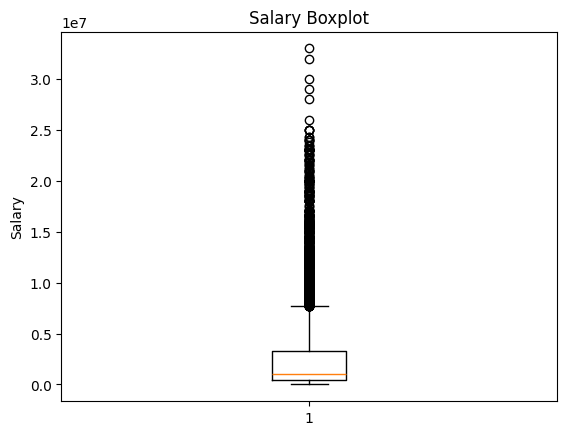

In [140]:
# Create a boxplot to see if salary has extreme values
plt.boxplot(y_train)

plt.title('Salary Boxplot')
plt.ylabel('Salary')

plt.show()

The salary boxplot showed several high salary values. These were kept because they may represent genuinely highly paid players rather than incorrect data. Removing them could also remove valid information that is useful for predicting salary.

After cleansing and transformation, the data is ready for machine learning.

Missing values have been handled, categorical variables have been converted into numerical form, the features and target have been separated, and the data has been divided into training and testing sets.

Numerical features have also been scaled. Salary outliers were investigated and kept because they may represent genuine high-earning players rather than incorrect data.

### Step 4: Machine Learning Modelling

#### Naive Baseline Model

In [141]:
# finding the average training salary
average_salary = y_train.mean()

# predicting the average salary for all player in testing data
baseline_predictions = [average_salary] * len(y_test)

# calculating average prediction error for naive baseline model
baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

# calculating R2 for the baseline
baseline_r2 = r2_score(
    y_test,
    baseline_predictions
)

print("Baseline R2:", round(baseline_r2, 3))
print("Baseline MAE:", round(baseline_mae, 2))

Baseline R2: -0.0
Baseline MAE: 2536745.43


#### Linear Regression Model and Model Evaluation

In [142]:
# creating linear regression model
model = LinearRegression()

# training model using using training data
model.fit(X_train, y_train)

# using train model to predict salaries
predictions = model.predict(X_test)

In [143]:
# calculating average prediction error for linear regression model
model_mae = mean_absolute_error(
    y_test,
    predictions
)

# calculating how much salary variation is explained by model
model_r2 = r2_score(
    y_test,
    predictions
)

print("Linear Regression MAE:", round(model_mae, 2))
print("Linear Regression R2:", round(model_r2, 3))

Linear Regression MAE: 829489.55
Linear Regression R2: 0.846


#### Baseline vs Linear Regression

In [144]:
print("Baseline MAE:", round(baseline_mae, 2))
print("Linear Regression MAE:", round(model_mae, 2))

# calculating how much the MAE improved
improvement = (
    (baseline_mae - model_mae)
    / baseline_mae
) * 100

print("Improvement:", round(improvement, 2), "%")

Baseline MAE: 2536745.43
Linear Regression MAE: 829489.55
Improvement: 67.3 %


In [145]:
# comparing some actual salaries with predicted salaries
results = pd.DataFrame({
    'Actual Salary': y_test,
    'Predicted Salary': predictions
})

results.head(10)

,Actual Salary,Predicted Salary
16088,2800000,2.215978e+06
20804,440000,9.646138e+05
14984,2700000,3.346629e+06
21507,1080000,1.528262e+06
13686,525000,7.202894e+05
25059,4200000,2.599575e+06
17962,10500000,8.382886e+06
15869,316300,9.665232e+05
24729,507800,1.287639e+06
14783,2300000,2.112802e+06


#### Improvements using Random Forest Regression

In [146]:
# creating the random forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# training the model
rf_model.fit(X_train, y_train)

# predicting the salary
rf_predictions = rf_model.predict(X_test)

# calculating average prediction error for random forest model
rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

# calculating R2 for Random Forest
rf_r2 = r2_score(
    y_test,
    rf_predictions
)

print("Random Forest MAE:", round(rf_mae, 2))
print("Random Forest R2:", round(rf_r2, 3))

Random Forest MAE: 736514.29
Random Forest R2: 0.854


In [147]:
# comparing all model results
print("Baseline MAE:", round(baseline_mae, 2))
print("Baseline R2:", round(baseline_r2, 3))

print("")

print("Linear Regression MAE:", round(model_mae, 2))
print("Linear Regression R2:", round(model_r2, 3))

print("")

print("Random Forest MAE:", round(rf_mae, 2))
print("Random Forest R2:", round(rf_r2, 3))

Baseline MAE: 2536745.43
Baseline R2: -0.0

Linear Regression MAE: 829489.55
Linear Regression R2: 0.846

Random Forest MAE: 736514.29
Random Forest R2: 0.854


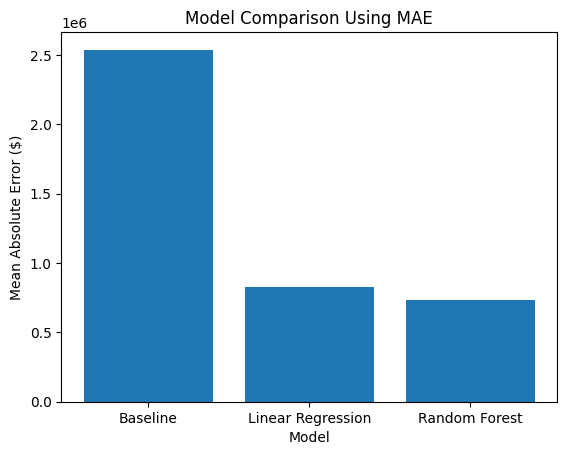

In [148]:
# comparing model MAE
models = ['Baseline', 'Linear Regression', 'Random Forest']

mae_values = [
    baseline_mae,
    model_mae,
    rf_mae
]

plt.bar(models, mae_values)

plt.title('Model Comparison Using MAE')
plt.xlabel('Model')
plt.ylabel('Mean Absolute Error ($)')

plt.xticks(rotation=0)

plt.show()

In [ ]:
# comparing model r2
models = ['Baseline', 'Linear Regression', 'Random Forest']

r2_values = [
    baseline_r2,
    model_r2,
    rf_r2
]

plt.bar(models, r2_values)

plt.title('Model Comparison Using R²')
plt.xlabel('Model')
plt.ylabel('R² Score')

plt.xticks(rotation=0)

plt.show()

This shows that Random Forest produced the most accurate salary predictions among the three models.

In [ ]:
# calculating improvement from Linear Regression to Random Forest

rf_improvement = (
    (model_mae - rf_mae) / model_mae
) * 100

print(
    "Random Forest improvement over Linear Regression:",
    round(rf_improvement, 2), "%"
)

Random Forest improvement over Linear Regression: 11.21 %


In [ ]:
# comparing  actual and Random Forest predicted salaries
rf_results = pd.DataFrame({
    'Actual Salary': y_test,
    'Predicted Salary': rf_predictions
})

rf_results.head(10)

,Actual Salary,Predicted Salary
16088,2800000,2299463.92
20804,440000,557231.00
14984,2700000,3029548.81
21507,1080000,1878650.01
13686,525000,761055.00
25059,4200000,2768127.48
17962,10500000,9374338.85
15869,316300,836607.22
24729,507800,820431.75
14783,2300000,2326436.16


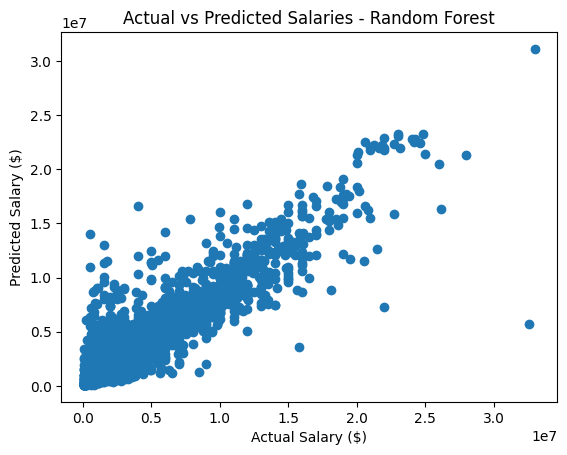

In [ ]:
plt.scatter(y_test, rf_predictions)

plt.title('Actual vs Predicted Salaries - Random Forest')
plt.xlabel('Actual Salary ($)')
plt.ylabel('Predicted Salary ($)')

plt.show()

## Report

## Table of Contents
1. Introduction with Value Based Problem Statement  
2. Problem Formulation  
3. Data Wrangling on Multiple Tables  
4. Data Cleansing and Transformation  
5. Machine Learning Model  
6. Summary and Further Improvements  
7. Reflection

## 1. Introduction with Value Based Problem Statement
Baseball teams need to decide how much to pay their players. They may consider things such as a player's experience, performance and team situation when making salary decisions.

This project uses historical Major League Baseball data to predict a player's current salary. A useful salary prediction model can help show which factors are related to higher or lower salaries. It may also help teams with salary and player planning.

The main aim of this project is to combine and prepare data from several tables, create useful features and compare simple machine learning models to see how accurately player salary can be predicted.

[Word Count: 102]

## 2. Problem Formulation
TThis project is a regression problem because the target variable, player salary, is numerical. In simple terms, the model is trying to predict a number instead of a category.

Four tables were selected for this project: salary, player, appearances and team. The salary table was used as the main table because it contains the target variable, salary, together with player, team and year information.

The player table provides personal information such as birth year, height, weight, batting hand and throwing hand. The appearances table contains information about games played and games started. The team table provides team information such as team rank, wins, losses and attendance.

Before combining the tables, I explored the data by checking the table shapes, columns, data types, missing values and year ranges. The salary table contains 25,575 records and covers the years 1985 to 2015.
The salary distribution is right-skewed. This means most players have lower salaries, while only a small number of players have very high salaries.

The prediction question for this project is:
Can a player's current salary be predicted using previous salary, player characteristics, game appearances and team information?

Previous salary was included because a player's salary from the previous season may contain useful information about the player's experience and value.

[Word Count: 209]


## 3. Data Wrangling on Multiple Tables  
The salary table was used as the base table because salary is the target variable. Information from the player, appearances and team tables was added using left joins.

Only the columns needed for the prediction problem were selected before merging. The tables were connected using player_id, year and team_id where appropriate.

Three new features were created:
1. age was calculated by subtracting birth_year from the season year.
2. win percentage was calculated using: wins ÷ (wins + losses)
3. previous salary was created using salary information from the immediately previous year.

Some players had more than one salary record in the same year. Before creating previous salary, I grouped the salary data by player_id and year and summed the salaries. This prevented the later merge from creating extra rows.

The year in the previous salary table was then moved forward by one year. For example, a player's 2009 salary was moved to 2010 so that it could be joined to the player's 2010 record.

After the new features were created, the salary, player, appearances and team tables were merged into one player-season dataset.

The final dataset had 25,575 rows, which was the same number of rows as the original salary table. This showed that the merging did not create extra records.

There were also zero duplicated rows. Row counts, duplicates and missing values were checked after merging to make sure the tables were combined correctly.

[Word Count: 235]


## 4. Data Cleansing and Transformation
After merging the tables, I selected the numerical and categorical features needed for modelling.

The numerical features included:
- year
- height
- weight
- previous salary
- game appearances
- team rank
- attendance
- age
- win percentage

The categorical features included:
- league
- batting hand
- throwing hand
- division winner
- league winner
- World Series winner

Missing values were checked before modelling. Previous salary had many missing values because some players did not have a salary recorded in the immediately previous season. Other features also had some missing values after the tables were merged.

For the final model, I removed rows that had missing values in the modelling features. The dataset went from 25,575 rows to 17,573 rows. A total of 8,002 rows, or 31.29%, were removed because they had missing information. This is a limitation because some useful player records may have been lost. However, it allowed the model to use only complete records.

Categorical variables cannot be used directly by the regression models. Therefore, one-hot encoding was used to change the categorical variables into numerical values.

The data was then divided into 70% training data and 30% testing data.

The numerical features had very different ranges. For example, previous salary and attendance had large values, while win percentage had a much smaller range. I used StandardScaler to put these numerical features on a more comparable scale.

Salary outliers were also examined. Some players had much higher salaries than most other players. These values were kept because they may represent genuine high-paid players instead of data errors. Removing them could remove useful information from the dataset.

[Word Count: 258]


## 5. Machine Learning Model 
Three models were compared:
1.	Naive baseline
2.	Linear Regression
3.	Random Forest Regression

The naive baseline predicted the average salary from the training data for every player. This provided a simple starting point. A useful machine learning model should perform better than this baseline.

The models were evaluated using Mean Absolute Error (MAE) and R².

MAE tells us the average difference between the predicted salary and the real salary. A smaller MAE means the predictions are closer to the actual salaries.

R² tells us how much of the difference in player salary is explained by the model. A higher R² means the model explains more of the salary variation.


The naive baseline produced an MAE of about $2.54 million and an R² close to 0. This means its salary predictions had large errors and it explained very little of the differences in player salaries.

Linear Regression performed much better. It produced an MAE of about $829,490 and an R² of 0.846.

Random Forest Regression gave the best result. It produced an MAE of about $736,514 and an R² of 0.854.

These results show that the prepared features contain useful information for predicting player salary.

Random Forest performed slightly better than Linear Regression. One possible reason is that Random Forest can capture more complex and non-linear relationships between the features and salary.

Previous salary may also be an important predictor because a player's salary often carries information from one season to the next. Further analysis of feature importance could be used to confirm this.

[Word Count: 254]


## 6. Summary and Further Improvements 
This project successfully combined four baseball tables into one player-season dataset and used the prepared data to predict player salary.

Three useful features were created from the original data: age, team win percentage and previous salary.

A problem with multiple salary records for the same player and year was also found when creating previous salary. The salary records were grouped before the merge so that extra rows were not created. This helped keep the final dataset at the same number of rows as the original salary table.

The model comparison showed that both machine learning models performed much better than the naïve baseline.

Random Forest gave the best result, with an MAE of about $0.74 million and an R² of about 0.85. This shows that previous salary, player information, appearances and team information contain useful information for predicting salary.

There are several ways this project could be improved.
More player performance features could be added, such as batting or pitching statistics. I could also test different ways of handling missing values instead of removing all incomplete rows.

The Random Forest settings could also be tuned to see whether its performance can be improved further.

Another improvement would be to use a chronological train-test split. Earlier seasons could be used for training, while later seasons could be used for testing. This would be closer to a real salary prediction situation.

Future work could also use only information that would be available before the salary was decided. This would make the prediction more realistic and reduce the risk of using information from later in the same season.

[Word Count: 265]
________________________________________


## 7. Reflection 
This assignment helped me understand the full data wrangling process. I started with raw data and prepared it until it was ready for a machine learning model.

I learned that combining tables is not only about using merge. It is also important to understand the structure of each table and check that the joining keys do not accidentally create extra rows.

Creating the previous salary feature helped me understand why grouping data before a merge can be important. I also practised creating new features using calculations and time-based information.

I used several techniques from the module, including checking missing values, one-hot encoding categorical variables, feature scaling and examining outliers.

I also learned how to compare a naïve baseline with machine learning models using MAE and R².

One area I could improve is the way I handled missing values. I removed rows with missing modelling values, but this removed a large part of the dataset. In future, I would compare different imputation methods instead of only removing missing records.

I would also test more player-performance features and different model settings before selecting the final model.

[Word Count: 184]
